# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:  
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**  
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Group 11 Section 1"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?

c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.


### a. 
PCA is a linear dimensionality reduction technique that seeks to preserve global variance, but it fails to capture complex, non-linear relationships in high-dimensional data. If the data lies on a curved or twisted manifold, PCA will project it flat, often causing distinct groups to overlap. Non-linear methods like t-SNE and UMAP are more effective in these contexts because they focus on preserving local neighborhood structures, allowing them to successfully untangle and separate complex, non-linear clusters.

### b. 
t-SNE: Exceptional at revealing local structure and creating visually distinct clusters for high-dimensional data exploration. However, it is computationally expensive and slow for very large datasets; fails to preserve global structure (the distance between distinct clusters is largely arbitrary); struggles to project new, unseen data into an existing plot.

UMAP: Significantly faster and more scalable than t-SNE. In addition, it strikes a better balance by preserving both local neighborhoods and a meaningful amount of global structure. On the other hand, it still requires careful hyperparameter tuning and lacks the strict mathematical interpretability of PCA's variance axes. 

Preference: UMAP is generally preferred for larger datasets, integration into machine learning pipelines, or when global structure matters. t-SNE is typically reserved for smaller datasets where maximum local cluster separation is the only goal.

### c.
t-SNE (Perplexity): Perplexity determines the number of nearest neighbors each point considers when evaluating local structure. A low perplexity focuses strictly on local variations (which can fragment clusters into noise), while a high perplexity incorporates more global information but may cause distinct clusters to merge.

UMAP (n_neighbors): Similar to perplexity, it controls the balance between local and global structure by setting the size of the local neighborhood. Small values focus on very local, fine-grained structure, while large values look at broader, global patterns.

UMAP (min_dist): Controls how tightly points are allowed to pack together in the final projection. Lower values result in denser, more highly compressed clusters, while higher values allow points to spread out, preserving more of the broad topological structure.

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

penguins = pd.read_csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv")
penguins = penguins.dropna()
penguins.species.value_counts()

selected_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

X = penguins[selected_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

penguins_scaled = pd.DataFrame(X_scaled, columns=selected_features, index=penguins.index)
penguins_scaled.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.896042,0.780732,-1.426752,-0.568475
1,-0.822788,0.119584,-1.069474,-0.506286
2,-0.676280,0.424729,-0.426373,-1.190361
4,-1.335566,1.085877,-0.569284,-0.941606
5,-0.859415,1.747026,-0.783651,-0.692852


b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

In [2]:
!conda install -y -c conda-forge umap-learn

2 channel Terms of Service accepted
Channels:
 - conda-forge
 - defaults
Platform: osx-64
Solving environment: done

# All requested packages already installed.



In [4]:
!conda install -y "numpy<2.0"

2 channel Terms of Service accepted
Channels:
 - defaults
Platform: osx-64
Solving environment: done

## Package Plan ##

  environment location: /opt/miniconda3/envs/py3114

  added / updated specs:
    - numpy[version='<2.0']


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    blas-1.0                   |              mkl           6 KB
    intel-openmp-2023.1.0      |   ha357a0b_43548         638 KB
    libgfortran-5.0.0          |11_3_0_hecd8cb5_28         142 KB
    libgfortran5-11.3.0        |      h9dfd629_28         1.4 MB
    libopenblas-0.3.29         |       h3f8574a_0         6.8 MB
    llvm-openmp-19.1.7         |       h5048363_2         355 KB
    mkl-2023.1.0               |   h8e150cf_43560       181.0 MB
    mkl-service-2.4.0          |  py311h46256e1_2          57 KB
    mkl_fft-1.3.8              |  py311h6c40b1e_0         204 KB
    mkl_random-1.2.4           |  py311h

In [6]:
!pip install "numpy<2" --force-reinstall

  Using cached numpy-1.26.4-cp311-cp311-macosx_10_9_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-macosx_10_9_x86_64.whl (20.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.2.2 which is incompatible.


In [9]:
!pip uninstall -y tensorflow

Found existing installation: tensorflow 2.16.2
Uninstalling tensorflow-2.16.2:
  Successfully uninstalled tensorflow-2.16.2


/opt/miniconda3/envs/py3114/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


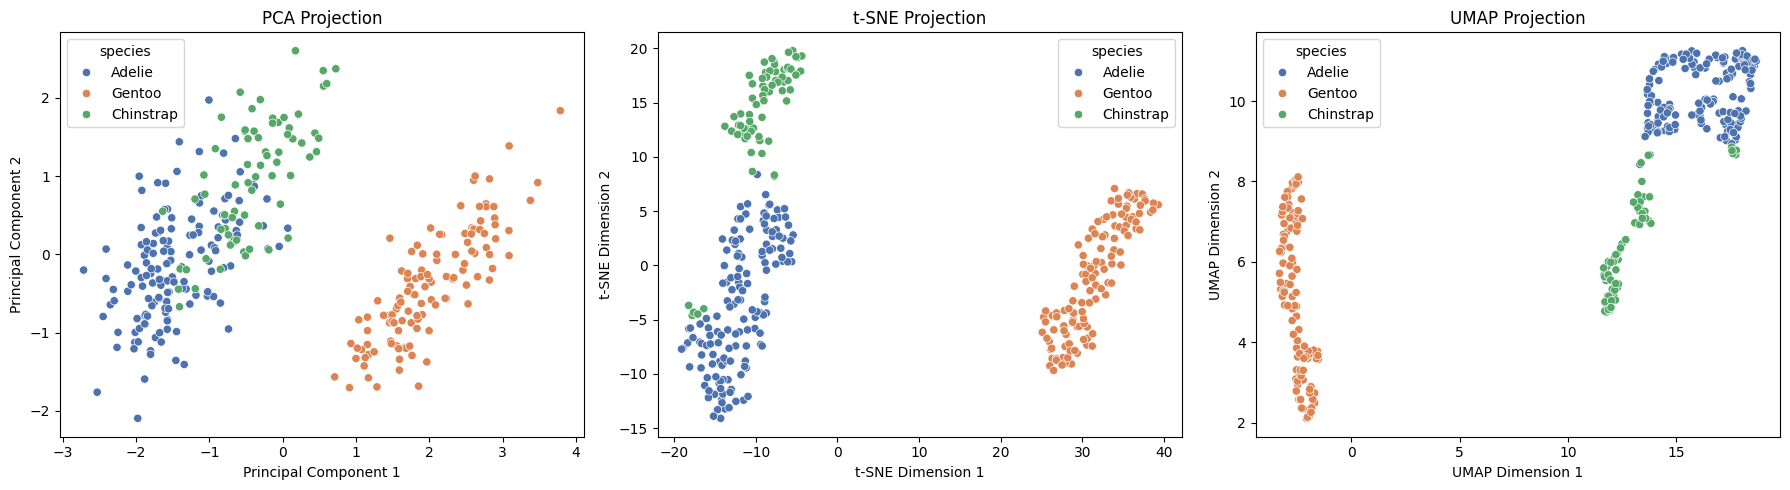

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# UMAP
umap_model = umap.UMAP(n_components=2, random_state=42)
X_umap = umap_model.fit_transform(X_scaled)

# create visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# PCA plot
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=penguins['species'],
    palette="deep",
    ax=axes[0]
)
axes[0].set_title('PCA Projection')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# t-SNE plot
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=penguins['species'],
    palette="deep",
    ax=axes[1]
)
axes[1].set_title('t-SNE Projection')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')

# UMAP plot
sns.scatterplot(
    x=X_umap[:, 0], y=X_umap[:, 1],
    hue=penguins['species'],
    palette="deep",
    ax=axes[2]
)
axes[2].set_title('UMAP Projection')
axes[2].set_xlabel('UMAP Dimension 1')
axes[2].set_ylabel('UMAP Dimension 2')

plt.tight_layout()
plt.show()

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.


According to the resulting plots, UMAP produced the most visibly separable clusters with clear boundaries between the species. Except for some Chinstrap points, all data points are clustered clearly and visibly separate from others. 

Adelie (blue) and Chinstrap (green) seem to overlap in the PCA and t-SNE projection, but it doesn't in the UMAP projection.

Since PCA is a linear dimensionality reduction, non-linear relationships may cause a mix in distinct groups and cause an overlap. WIth this information, it seems as if the data in non-linear. On the other hand, t-SNE and UMAP are both non-linear techniques, explaining why both performed better than PCA.

Strengths & Limitations:

PCA - PCA is computationally fast and preserves a global data structure, allowing one to interpret exactly how much variance each component explains. However, its reliance on linear transformations leads to failure in separating clusters that require non-linear boundaries.

t-SNE - It is highly effective at revealing local structure and separating non-linear clusters. On the other hand, it could be computationally heavy for large datasets and destroys global structure.

UMAP - UMAP provides the cleanest separation in this dataset, and is designed to find a balance between preserving local neighborhood structure and global data geometry. However, it requires tuning hyperparameters to get optimal representation.

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

/opt/miniconda3/envs/py3114/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/miniconda3/envs/py3114/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/miniconda3/envs/py3114/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


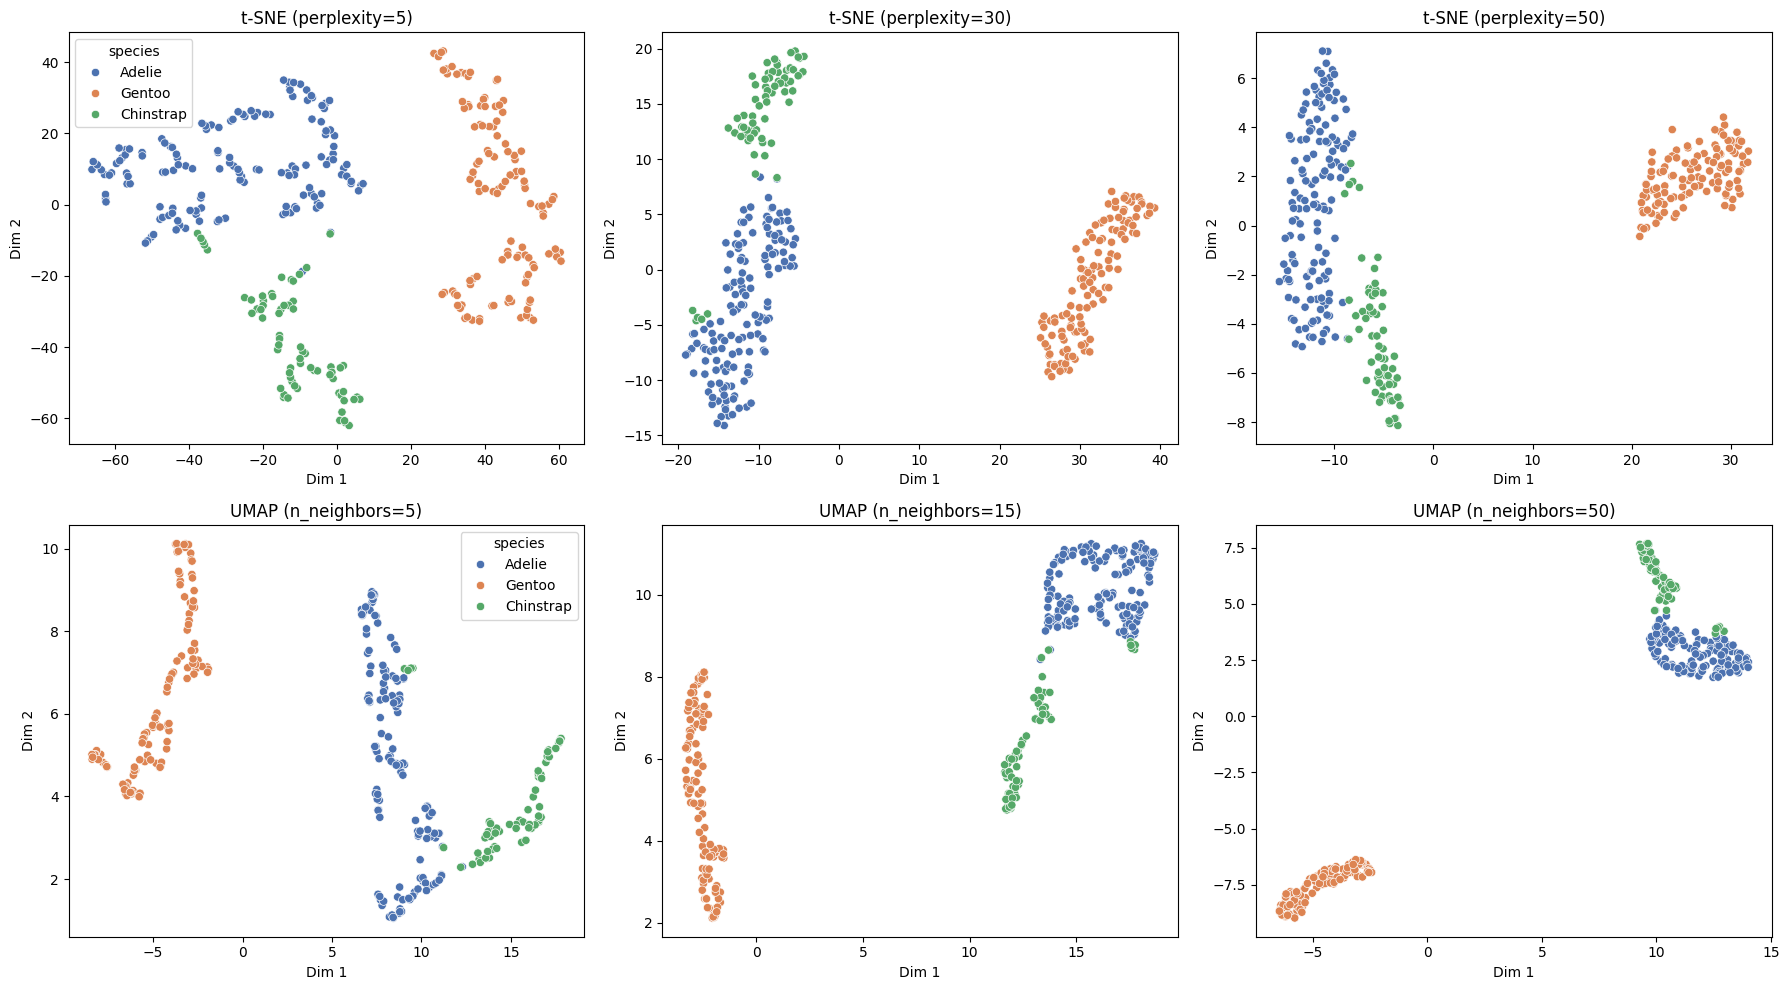

In [11]:
# Define hyperparameters
perplexities = [5, 30, 50]
n_neighbors_list = [5, 15, 50]

# Create 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# t-SNE
for i, p in enumerate(perplexities):
    tsne = TSNE(n_components=2, perplexity=p, random_state=42)
    tsne_result = tsne.fit_transform(X_scaled)
    
    sns.scatterplot(
        x=tsne_result[:, 0], y=tsne_result[:, 1],
        hue=penguins['species'],
        palette="deep",
        ax=axes[0, i]
    )
    axes[0, i].set_title(f't-SNE (perplexity={p})')
    axes[0, i].set_xlabel('Dim 1')
    axes[0, i].set_ylabel('Dim 2')
    if i > 0:
        axes[0, i].get_legend().remove()

# U-MAP
for i, n in enumerate(n_neighbors_list):
    umap_reducer = umap.UMAP(n_components=2, n_neighbors=n, random_state=42)
    umap_result = umap_reducer.fit_transform(X_scaled)
    
    sns.scatterplot(
        x=umap_result[:, 0], y=umap_result[:, 1],
        hue=penguins['species'],
        palette="deep",
        ax=axes[1, i]
    )
    axes[1, i].set_title(f'UMAP (n_neighbors={n})')
    axes[1, i].set_xlabel('Dim 1')
    axes[1, i].set_ylabel('Dim 2')
    if i > 0:
        axes[1, i].get_legend().remove()

plt.tight_layout()
plt.show()

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

For both t-SNE and UMAP, as perplexity and n_neighbors increases, the clusters go from scattered sub-groups to denser and more tightly packed clusters. The best settings seem to be perplexity=30 and n_neighbors=15 as they find a balance between avoiding too much noise while maintaining clear boundaries between species.

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual. 

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques. 

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

/opt/miniconda3/envs/py3114/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


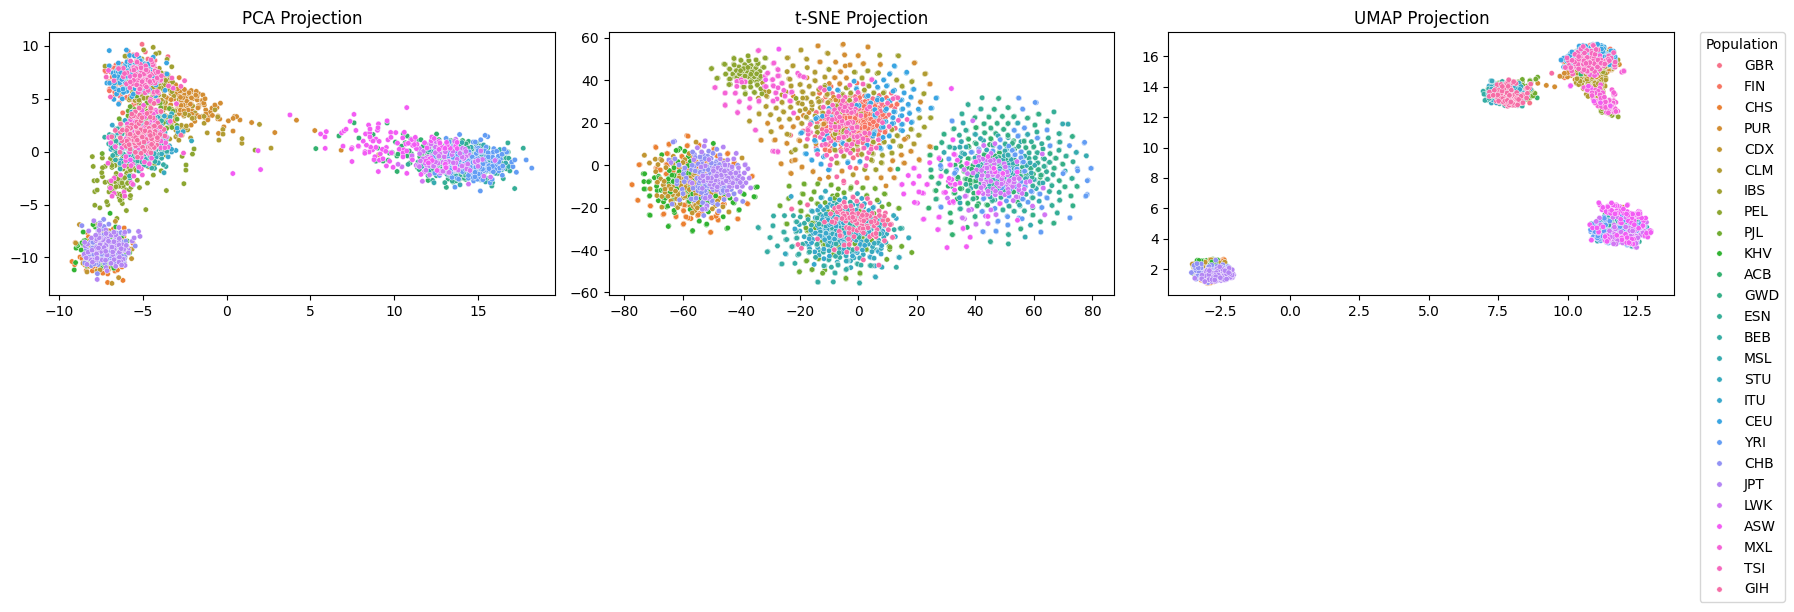

In [15]:
import numpy as np

# a. 
X = np.load("genome_data_lab3.npy")
labels = pd.read_csv("population_labels_lab3.txt", header=None)
pop_labels = labels[0]

# b.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# c.
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(X_scaled)

tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(X_scaled)

umap_reducer = umap.UMAP(n_components=2, random_state=42)
umap_result = umap_reducer.fit_transform(X_scaled)

# d.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# PCA - legend turned off
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=pop_labels, ax=axes[0], s=15, legend=False)
axes[0].set_title('PCA Projection')

# t-SNE - legend turned off
sns.scatterplot(x=tsne_result[:, 0], y=tsne_result[:, 1], hue=pop_labels, ax=axes[1], s=15, legend=False)
axes[1].set_title('t-SNE Projection')

# UMAP - legend kept, but moved outside the plot
sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], hue=pop_labels, ax=axes[2], s=15)
axes[2].set_title('UMAP Projection')

# Move the legend outside the 3rd plot
axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0, title='Population')

plt.tight_layout()
plt.show()

PCA - The projection shows a continuous, somewhat overlapping spread of the data. This happens because PCA is a linear method that preserves global variance, meaning it captures broad genetic gradients, but fails to separate tightly knit subgroups.

t-SNE - This method groups similar populations together into distinct regions, but the clusters are somewhat scattered.

UMAP - The projection condenses the populations into a few highly isolated islands with a huge empty space between them.

Best Separation: UMAP. 

Genomic datasets are extremely high-dimensional and often contain a lot of noise. When you run PCA first, you filter out that noise and keep only the most significant underlying genetic signals. Running t-SNE or UMAP on this data significantly reduces computational time, and also results in cleaner clusters because the non-linear algorithms don't get distracted by the low-variance features of the raw dataset.

Trade-offs:

PCA: Offers maximum interpretability. The axes represent actual mathematical variance, and global distances between points are perfectly preserved. However, its performance is poor, though it is computationally the fastest.

t-SNE: Offers excellent visual separation but terrible global interpretability. The distances between distant clusters in a t-SNE plot are virtually meaningless, and it is computationally heavy on large raw datasets.

UMAP: Acts as a strong middle ground. It provides exceptional visual separation  and is much faster computationally. While its axes still lack the strict mathematical meaning of PCA components, UMAP preserves significantly more of the data's global topological structure than t-SNE does.

## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE